# New York yellow taxi demand: exploratory analysis

This notebook runs each query of the SQL library in `src/taxi_demand/sql/analysis/` against the
DuckDB warehouse that `make build` creates, and shows its result. The written findings are in
`reports/findings.md`; the dashboard is in `dashboard/app.py`.

Every query reads usable trips only. The data quality audit (last section) shows how many source
rows each check removed.

In [1]:
WAREHOUSE = "../artifacts/taxi.duckdb"
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from portfolio_common.plotting import apply_style

from taxi_demand.warehouse import run_query

%matplotlib inline
apply_style()
pd.set_option("display.float_format", "{:,.4g}".format)
con = duckdb.connect(WAREHOUSE, read_only=True)

## a01_monthly_trend

Monthly demand and revenue from usable trips.

In [2]:
result = run_query(con, "a01_monthly_trend")
result.head(30)

,month,trips,trips_per_day,total_usd,mean_fare_usd,card_tip_rate
0,1,2.806e+06,9.051e+04,7.579e+07,18.17,0.2277
1,2,2.84e+06,9.792e+04,7.652e+07,18.13,0.2272
2,3,3.365e+06,1.085e+05,9.266e+07,18.84,0.2254
3,4,3.34e+06,1.113e+05,9.302e+07,19.13,0.2247
4,5,3.536e+06,1.141e+05,1.013e+08,19.8,0.2228
5,6,3.347e+06,1.116e+05,9.469e+07,19.57,0.2218
6,7,2.894e+06,9.335e+04,8.239e+07,19.67,0.2174
7,8,2.786e+06,8.986e+04,7.987e+07,19.84,0.2161
8,9,3.394e+06,1.131e+05,9.868e+07,20.25,0.2188
9,10,3.581e+06,1.155e+05,1.038e+08,19.96,0.2219


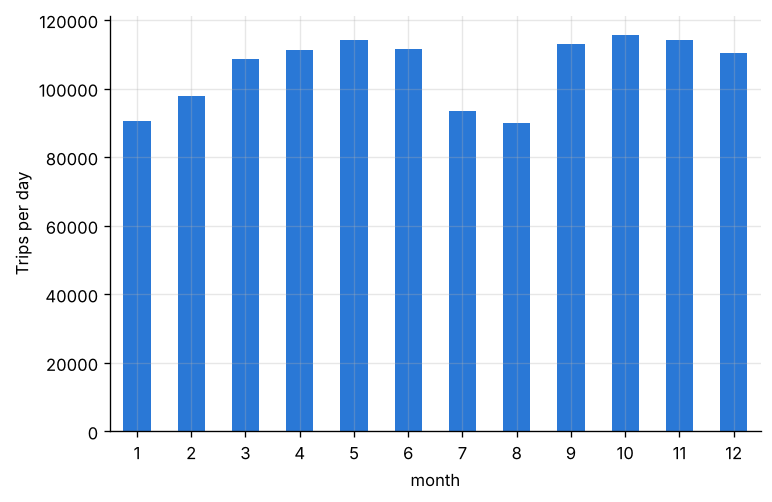

In [3]:
ax = result.plot.bar(
    x="month", y="trips_per_day", legend=False, color="#2a78d6", rot=0
)
ax.set_ylabel("Trips per day")
plt.show()

## a02_hour_weekday

Mean trips per hour for each weekday (1 Monday to 7 Sunday) and hour of pickup.

In [4]:
result = run_query(con, "a02_hour_weekday")
result.head(30)

,weekday,hour,mean_trips
0,1,0,"1,537"
1,1,1,789.4
2,1,2,465.6
3,1,3,345
4,1,4,422.1
5,1,5,722.9
6,1,6,"1,691"
7,1,7,"3,260"
8,1,8,"4,384"
9,1,9,"4,444"


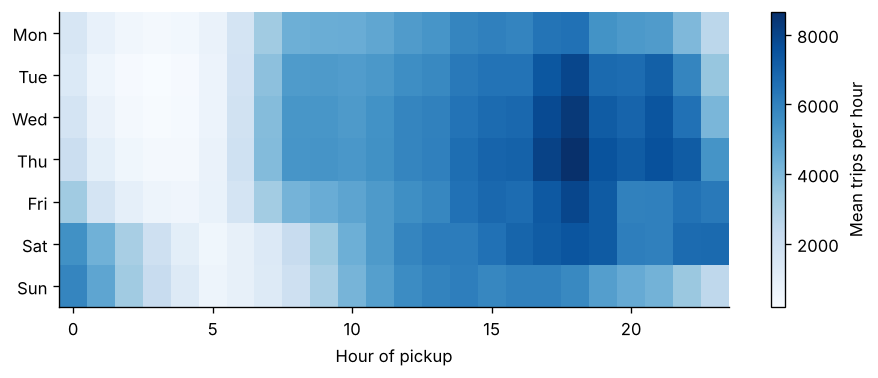

In [5]:
grid = result.pivot(index="weekday", columns="hour", values="mean_trips")
fig, ax = plt.subplots(figsize=(9, 3.2))
image = ax.imshow(grid, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xlabel("Hour of pickup")
ax.grid(False)
fig.colorbar(image, label="Mean trips per hour")
plt.show()

## a03_speed_by_hour

Mean trip speed (total distance over total time) by hour, weekdays against weekends.

In [6]:
result = run_query(con, "a03_speed_by_hour")
result.head(30)

,day_type,hour,mean_speed_mph,trips
0,Weekday,0,18.81,5.183e+05
1,Weekday,1,19.31,2.452e+05
2,Weekday,2,18.39,1.324e+05
3,Weekday,3,20.05,8.746e+04
4,Weekday,4,23.03,9.702e+04
5,Weekday,5,21.26,1.844e+05
6,Weekday,6,16.49,4.567e+05
7,Weekday,7,12.78,9.405e+05
8,Weekday,8,10.83,1.278e+06
9,Weekday,9,10.45,1.297e+06


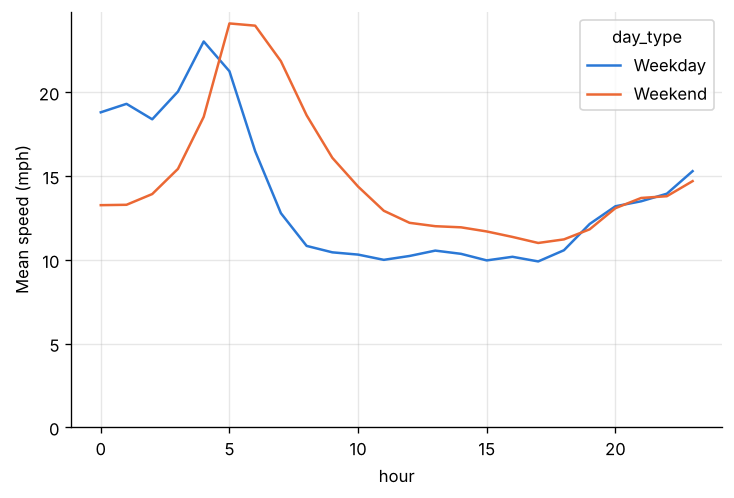

In [7]:
speed = result.pivot(index="hour", columns="day_type", values="mean_speed_mph")
ax = speed.plot(color=["#2a78d6", "#eb6834"])
ax.set_ylabel("Mean speed (mph)")
ax.set_ylim(bottom=0)
plt.show()

## a04_weather_effect

Demand index by weather class, holidays left out. An index of 1.0 equals the mean of the non holiday days with the same weekday in the same month. ci95 is the half width of a normal approximation 95 percent interval for the mean index.

In [8]:
result = run_query(con, "a04_weather_effect")
result.head(30)

,weather_class,days,mean_demand_index,sd_demand_index,ci95,mean_fare_usd,mean_duration_min
0,rain 10 mm or more,28,1.052,0.1115,0.0413,18.92,16.54
1,rain 1 to 10 mm,65,1.002,0.09013,0.02191,19.53,16.9
2,"dry, under 1 mm",255,0.9954,0.08533,0.01047,19.49,16.78
3,snow 10 mm or more,5,0.9204,0.1174,0.1029,17.68,14.53


## a05_zone_concentration

Pickup zones ranked by trips, with their share and the cumulative share of all trips.

In [9]:
result = run_query(con, "a05_zone_concentration")
result.head(30)

,zone_rank,zone,borough,trips,mean_total_usd,share,cumulative_share
0,1,Upper East Side South,Manhattan,1.844e+06,20.74,0.0476,0.0476
1,2,Midtown Center,Manhattan,1.827e+06,25.16,0.04717,0.09477
2,3,JFK Airport,Queens,1.725e+06,81.35,0.04454,0.1393
3,4,Upper East Side North,Manhattan,1.67e+06,21.14,0.04312,0.1824
4,5,Midtown East,Manhattan,1.357e+06,24.51,0.03504,0.2175
5,6,Times Sq/Theatre District,Manhattan,1.303e+06,28.78,0.03364,0.2511
6,7,Penn Station/Madison Sq West,Manhattan,1.294e+06,25.4,0.03342,0.2845
7,8,Lincoln Square East,Manhattan,1.262e+06,22.33,0.03258,0.3171
8,9,LaGuardia Airport,Queens,1.219e+06,67.5,0.03148,0.3486
9,10,Murray Hill,Manhattan,1.12e+06,24.24,0.02891,0.3775


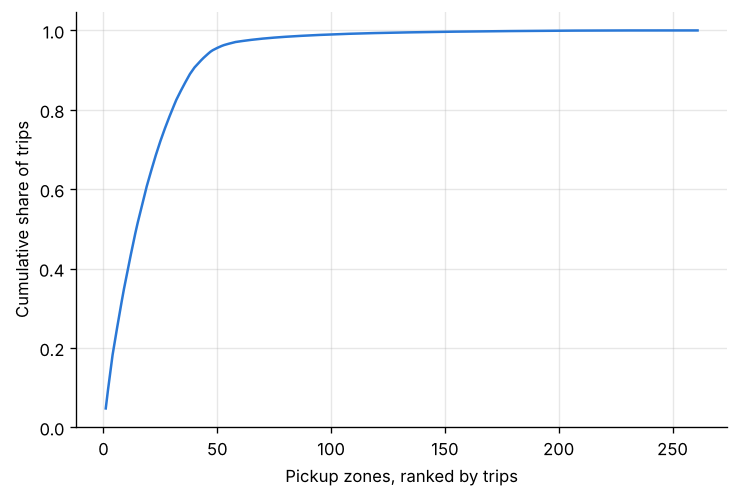

In [10]:
ax = result.plot(
    x="zone_rank", y="cumulative_share", legend=False, color="#2a78d6"
)
ax.set_ylabel("Cumulative share of trips")
ax.set_xlabel("Pickup zones, ranked by trips")
plt.show()

## a06_tip_rate

Tip as a share of fare on credit card trips by pickup borough and hour. Cash tips are not recorded in the source, so cash trips are left out.

In [11]:
result = run_query(con, "a06_tip_rate")
result.head(30)

,borough,hour,card_trips,card_tip_rate
0,Bronx,0,199,0.1664
1,Bronx,1,106,0.2222
2,Bronx,2,70,0.1734
3,Bronx,3,157,0.05769
4,Bronx,4,"1,217",0.0065
5,Bronx,5,"2,886",0.001463
6,Bronx,6,"5,109",0.001529
7,Bronx,7,"4,832",0.006104
8,Bronx,8,"5,604",0.006023
9,Bronx,9,"5,952",0.004711


## a07_airport_trips

Trips that start or end at an airport zone (1 Newark, 132 JFK, 138 LaGuardia) against all other trips.

In [12]:
result = run_query(con, "a07_airport_trips")
result.head(30)

,trip_type,trips,share_of_trips,share_of_revenue,mean_total_usd,mean_distance_mi,mean_duration_min
0,Airport,3811849,0.09841,0.2711,77.82,13.37,39.21
1,Other,34920641,0.9016,0.7289,22.84,2.264,14.38


## a08_zone_cohorts

Pickup zones grouped by their January volume (quartile 1 is the busiest quarter of zones), with each group's monthly trips per day indexed to January = 100.

In [13]:
result = run_query(con, "a08_zone_cohorts")
result.head(30)

,volume_quartile,month,trips_per_day,index_january_100
0,1,1,8.908e+04,100
1,1,2,9.631e+04,108.1
2,1,3,1.062e+05,119.2
3,1,4,1.088e+05,122.1
4,1,5,1.112e+05,124.8
5,1,6,1.085e+05,121.8
6,1,7,9.091e+04,102.1
7,1,8,8.726e+04,97.96
8,1,9,1.095e+05,122.9
9,1,10,1.125e+05,126.3


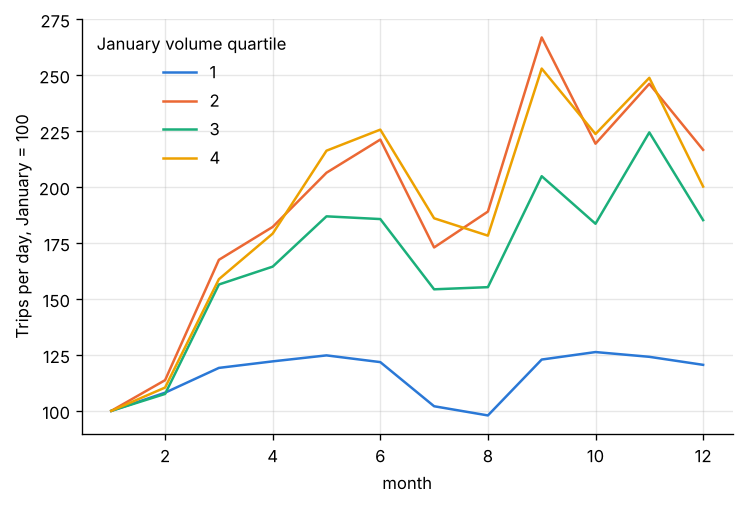

In [14]:
cohorts = result.pivot(
    index="month", columns="volume_quartile", values="index_january_100"
)
ax = cohorts.plot(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
ax.set_ylabel("Trips per day, January = 100")
ax.legend(title="January volume quartile", frameon=False)
plt.show()

## a09_payment_mix

Share of trips by payment group per month.

In [15]:
result = run_query(con, "a09_payment_mix")
result.head(30)

,month,payment,trips,share
0,1,Cash,4.165e+05,0.1485
1,1,Credit card,2.275e+06,0.8108
2,1,Other,1.144e+05,0.04078
3,2,Cash,3.911e+05,0.1377
4,2,Credit card,2.3e+06,0.81
5,2,Other,1.483e+05,0.05224
6,3,Cash,4.512e+05,0.1341
7,3,Credit card,2.55e+06,0.7577
8,3,Other,3.641e+05,0.1082
9,4,Cash,4.435e+05,0.1328


## a10_quality_audit

Source rows per quality check result.

In [16]:
result = run_query(con, "a10_quality_audit")
result.head(30)

,check_result,trips,share
0,kept,38732490,0.9408
1,"no charge, dispute or void",1086235,0.02638
2,zero distance,627266,0.01524
3,unknown zone,366527,0.008903
4,negative amount,274333,0.006663
5,speed under limit,35412,0.0008601
6,duration over limit,24902,0.0006049
7,non positive duration,12477,0.0003031
8,speed over limit,8539,0.0002074
9,distance over limit,1312,3.187e-05


## a11_card_tips_by_borough

Credit card trips by pickup borough: tip as a share of fare, and the share of trips with no tip.

In [17]:
result = run_query(con, "a11_card_tips_by_borough")
result.head(30)

,borough,card_trips,card_tip_rate,zero_tip_share,median_tip_rate_when_tipped
0,Manhattan,26844735,0.2327,0.04433,0.2661
1,Queens,2699520,0.2043,0.08232,0.2313
2,Brooklyn,263299,0.05769,0.6996,0.2336
3,Bronx,60081,0.01096,0.9496,0.2263
4,EWR,902,0.1438,0.2949,0.2018
5,Staten Island,139,0.1763,0.259,0.2514
